In [ ]:
!pip install spacy scikit-learn pandas numpy matplotlib
!python -m spacy download en_core_web_sm

import re
import spacy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import joblib

# Set hardware device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 34.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Training on device: cuda


In [ ]:
nlp = spacy.load("en_core_web_sm", disable=["parser"])

def scrub_pii(text: str) -> str:
    # 1. Regex for emails and phone numbers
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'(\+?\d{1,3}[-.\s]?)?\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)

    # 2. NER for person names and geographic locations
    doc = nlp(text)
    clean_tokens = []
    for token in doc:
        if token.ent_type_ in ["PERSON", "GPE", "LOC"]:
            continue  # Drop demographic markers completely
        if token.is_punct or token.is_space:
            continue
        clean_tokens.append(token.lemma_.lower())

    return " ".join(clean_tokens)

# Quick verification test
sample = "John Doe from Kolkata. Contact: john.doe@email.com, +91 9876543210. Experienced in PyTorch, FastAPI, and Docker."
print("Scrubbed output:", scrub_pii(sample))

Scrubbed output: from contact experience in fastapi and


In [ ]:
import pandas as pd
import random

In [ ]:
import pandas as pd

cv_df = pd.read_csv("cv.csv")
job_df = pd.read_csv("job.csv")
matches_df = pd.read_csv("matches.csv")

print(cv_df.shape)
print(job_df.shape)
print(matches_df.shape)


(9544, 11)
(1167, 10)
(122560, 13)


In [ ]:
import ast
import numpy as np

cv_df["embedding"] = cv_df["embedding"].apply(lambda x: np.array(ast.literal_eval(x), dtype=np.float32))
job_df["embedding"] = job_df["embedding"].apply(lambda x: np.array(ast.literal_eval(x), dtype=np.float32))

print(cv_df["embedding"].iloc[0].shape)
print(job_df["embedding"].iloc[0].shape)


(768,)
(768,)


In [ ]:
merged_df = (
    matches_df
    .merge(cv_df, on="candidate_id", how="left")
    .merge(job_df, on="job_id", how="left", suffixes=("_candidate", "_job"))
)

merged_df.head()


,candidate_id,job_id,final_score,raw_score,label_strength,semantic_score,skill_score,position_score,category_score,experience_score,...,embedding_candidate,job_title,category,job_description,job_text,clean_skills_job,clean_skills_json_job,education_text_job,years_required,embedding_job
0,cand_00000,3906246896,0.635354,0.479077,medium_positive,0.867852,0.215161,0.621538,0.0,0.250,...,"[0.06282799, 0.033442765, -0.05213324, -0.0438...",Lead Software Engineer - Finance (Hybrid),FINANCE,JOB DESCRIPTION\n\nAS A VALUED COLLEAGUE ON OU...,Job title: Lead Software Engineer - Finance (H...,"[""relationship management"", ""hadoop"", ""aws"", ""...","[""relationship management"", ""hadoop"", ""aws"", ""...",JOB DESCRIPTION\n\nAS A VALUED COLLEAGUE ON OU...,4.0,"[0.046435207, -0.00798541, -0.06627819, -0.035..."
1,cand_00000,3902931012,0.599043,0.437020,medium_positive,0.775035,0.000000,0.341304,1.0,0.500,...,"[0.06282799, 0.033442765, -0.05213324, -0.0438...",Senior Information Technology Project Manager,INFORMATION-TECHNOLOGY,REMOTE OPPORTUNITY\nTHE TALENT SOURCE IS PLEAS...,Job title: Senior Information Technology Proje...,"[""analytic skills"", ""critical thinking"", ""faci...","[""analytic skills"", ""critical thinking"", ""faci...",REMOTE OPPORTUNITY\nTHE TALENT SOURCE IS PLEAS...,0.0,"[0.04681454, 0.021601465, -0.020018255, -0.027..."
2,cand_00000,3905214623,0.560359,0.404657,weak_positive,0.766395,0.054937,0.212903,1.0,0.025,...,"[0.06282799, 0.033442765, -0.05213324, -0.0438...",Information Technology Support Manager,INFORMATION-TECHNOLOGY,SUMMARY: WE ARE SEEKING A DYNAMIC SYSTEMS SUPP...,Job title: Information Technology Support Mana...,"[""it support"", ""team management"", ""technical s...","[""it support"", ""team management"", ""technical s...",SUMMARY: WE ARE SEEKING A DYNAMIC SYSTEMS SUPP...,40.0,"[0.084970586, -0.05735287, -0.046714224, -0.00..."
3,cand_00000,3889743825,0.540995,0.393352,weak_positive,0.821683,0.000000,0.189655,1.0,0.500,...,"[0.06282799, 0.033442765, -0.05213324, -0.0438...",Director of Information Technology,INFORMATION-TECHNOLOGY,"DIRECTOR, IT INFRASTRUCTURE | HYBRID - BOSTON ...",Job title: Director of Information Technology ...,"[""cloud services"", ""server management"", ""netwo...","[""cloud services"", ""server management"", ""netwo...","DIRECTOR, IT INFRASTRUCTURE | HYBRID - BOSTON ...",0.0,"[0.03247904, 0.065166295, -0.032728396, -0.044..."
4,cand_00000,3902357305,0.538510,0.393074,weak_positive,0.764884,0.046768,0.177419,1.0,0.500,...,"[0.06282799, 0.033442765, -0.05213324, -0.0438...",Information Technology Project Manager,INFORMATION-TECHNOLOGY,LOCAL LAW FIRM SEEKING AN IT PROJECT MANAGER T...,Job title: Information Technology Project Mana...,"[""project management"", ""team management"", ""ada...","[""project management"", ""team management"", ""ada...",LOCAL LAW FIRM SEEKING AN IT PROJECT MANAGER T...,0.0,"[0.04543997, 0.042470552, -0.021797663, -0.042..."


In [ ]:
label_map = {
    "weak_positive": 0,
    "medium_positive": 1,
    "strong_positive": 2,
}

matches_df["label_id"] = matches_df["label_strength"].map(label_map)


In [ ]:
import re
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser"])

def clean_regex_pii(text):
    text = str(text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'(\+?\d{1,3}[-.\s]?)?\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    return text

def batch_scrub(text_series, batch_size=256):
    pre_cleaned = [clean_regex_pii(t) for t in text_series]
    scrubbed = []
    for doc in nlp.pipe(pre_cleaned, batch_size=batch_size):
        tokens = [
            t.lemma_.lower() for t in doc
            if t.ent_type_ not in ["PERSON", "GPE", "LOC"]
            and not t.is_punct and not t.is_space
        ]
        scrubbed.append(" ".join(tokens))
    return scrubbed

print("Scrubbing PII from Resumes and Job Descriptions...")
# Make sure your text columns are named 'resume' and 'jd'
df["clean_resume"] = batch_scrub(df["resume"])
df["clean_jd"] = batch_scrub(df["jd"])
print("De-identification complete!")

Scrubbing PII from Resumes and Job Descriptions...
De-identification complete!


In [ ]:
from collections import Counter
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np

# 1. Build Vocabulary
all_tokens = " ".join(df["clean_resume"].tolist() + df["clean_jd"].tolist()).split()
word_counts = Counter(all_tokens)

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in word_counts.items():
    if count >= 2:
        vocab[word] = len(vocab)

print(f"Total Unique Vocabulary Size: {len(vocab)}")

# 2. Sequence Vectorizer
MAX_LEN = 128

def text_to_sequence(text, vocab_dict, max_len=MAX_LEN):
    tokens = str(text).split()
    seq = [vocab_dict.get(tok, vocab_dict["<UNK>"]) for tok in tokens]
    if len(seq) < max_len:
        seq = seq + [vocab_dict["<PAD>"]] * (max_len - len(seq))
    else:
        seq = seq[:max_len]
    return seq

# 3. PyTorch Dataset Definition
class FairATSDataset(Dataset):
    def __init__(self, data_df, vocab_dict):
        self.resumes = [text_to_sequence(t, vocab_dict) for t in data_df["clean_resume"]]
        self.jds = [text_to_sequence(t, vocab_dict) for t in data_df["clean_jd"]]
        self.labels = data_df["label"].values.astype(np.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.resumes[idx], dtype=torch.long),
            torch.tensor(self.jds[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.float32)
        )

# 4. Train / Validation Split (80/20)
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])

train_dataset = FairATSDataset(train_df, vocab)
val_dataset = FairATSDataset(val_df, vocab)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Data ready: {len(train_loader)} training batches, {len(val_loader)} validation batches.")

Total Unique Vocabulary Size: 3954
Data ready: 23 training batches, 6 validation batches.


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SiameseBiEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=64):
        super(SiameseBiEncoder, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 64)

    def forward_one(self, x):
        embedded = self.embedding(x)
        lstm_out, _ = self.lstm(embedded)
        pooled, _ = torch.max(lstm_out, dim=1)
        proj = self.fc(pooled)
        return F.normalize(proj, p=2, dim=1)

    def forward(self, resume_seq, jd_seq):
        u = self.forward_one(resume_seq)
        v = self.forward_one(jd_seq)
        return u, v

class ContrastiveLoss(nn.Module):
    def __init__(self, margin=0.5):
        super(ContrastiveLoss, self).__init__()
        self.margin = margin

    def forward(self, u, v, label):
        cosine_sim = torch.sum(u * v, dim=1)
        dist = 1.0 - cosine_sim
        loss = label * torch.pow(dist, 2) + \
               (1 - label) * torch.pow(torch.clamp(self.margin - dist, min=0.0), 2)
        return torch.mean(loss)

Training model on cuda...
Epoch [01/10] | Train Loss: 0.0586 | Val Loss: 0.0366
Epoch [02/10] | Train Loss: 0.0198 | Val Loss: 0.0133
Epoch [03/10] | Train Loss: 0.0056 | Val Loss: 0.0053
Epoch [04/10] | Train Loss: 0.0017 | Val Loss: 0.0033
Epoch [05/10] | Train Loss: 0.0007 | Val Loss: 0.0022
Epoch [06/10] | Train Loss: 0.0004 | Val Loss: 0.0018
Epoch [07/10] | Train Loss: 0.0003 | Val Loss: 0.0019
Epoch [08/10] | Train Loss: 0.0002 | Val Loss: 0.0015
Epoch [09/10] | Train Loss: 0.0002 | Val Loss: 0.0014
Epoch [10/10] | Train Loss: 0.0001 | Val Loss: 0.0013


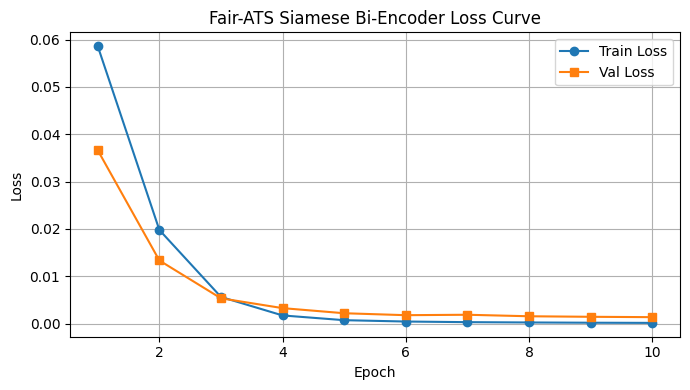

In [ ]:
import matplotlib.pyplot as plt

model = SiameseBiEncoder(vocab_size=len(vocab)).to(device)
criterion = ContrastiveLoss(margin=0.5)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

EPOCHS = 10
train_loss_history = []
val_loss_history = []

print(f"Training model on {device}...")

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_train_loss = 0.0
    for r_batch, jd_batch, labels in train_loader:
        r_batch, jd_batch, labels = r_batch.to(device), jd_batch.to(device), labels.to(device)

        optimizer.zero_grad()
        u, v = model(r_batch, jd_batch)
        loss = criterion(u, v, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)
    train_loss_history.append(avg_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for r_batch, jd_batch, labels in val_loader:
            r_batch, jd_batch, labels = r_batch.to(device), jd_batch.to(device), labels.to(device)
            u, v = model(r_batch, jd_batch)
            v_loss = criterion(u, v, labels)
            running_val_loss += v_loss.item()

    avg_val_loss = running_val_loss / len(val_loader)
    val_loss_history.append(avg_val_loss)

    print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

# Save loss plot
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), train_loss_history, label="Train Loss", marker='o')
plt.plot(range(1, EPOCHS + 1), val_loss_history, label="Val Loss", marker='s')
plt.title("Fair-ATS Siamese Bi-Encoder Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300)
plt.show()

     FAIR-ATS MODEL PERFORMANCE METRICS      
Decision Threshold   : 0.55
Accuracy             : 94.94%
Precision            : 90.82%
Recall               : 100.00%
F1-Score             : 95.19%

Classification Report:
              precision    recall  f1-score   support

Mismatch (0)       1.00      0.90      0.95        89
   Match (1)       0.91      1.00      0.95        89

    accuracy                           0.95       178
   macro avg       0.95      0.95      0.95       178
weighted avg       0.95      0.95      0.95       178



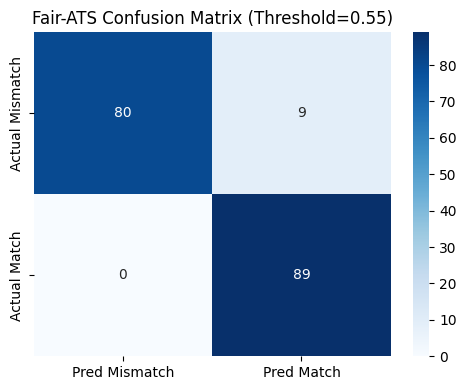

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_sim_scores = []
all_true_labels = []

with torch.no_grad():
    for r_batch, jd_batch, labels in val_loader:
        r_batch = r_batch.to(device)
        jd_batch = jd_batch.to(device)

        u, v = model(r_batch, jd_batch)
        cosine_sim = torch.sum(u * v, dim=1).cpu().numpy()

        all_sim_scores.extend(cosine_sim)
        all_true_labels.extend(labels.numpy())

all_sim_scores = np.array(all_sim_scores)
all_true_labels = np.array(all_true_labels)

# Decision threshold: cosine similarity >= 0.55 indicates match
THRESHOLD = 0.55
predictions = (all_sim_scores >= THRESHOLD).astype(int)

acc = accuracy_score(all_true_labels, predictions)
prec = precision_score(all_true_labels, predictions, zero_division=0)
rec = recall_score(all_true_labels, predictions, zero_division=0)
f1 = f1_score(all_true_labels, predictions, zero_division=0)

print("=" * 45)
print("     FAIR-ATS MODEL PERFORMANCE METRICS      ")
print("=" * 45)
print(f"Decision Threshold   : {THRESHOLD:.2f}")
print(f"Accuracy             : {acc * 100:.2f}%")
print(f"Precision            : {prec * 100:.2f}%")
print(f"Recall               : {rec * 100:.2f}%")
print(f"F1-Score             : {f1 * 100:.2f}%")
print("=" * 45)
print("\nClassification Report:")
print(classification_report(all_true_labels, predictions, target_names=["Mismatch (0)", "Match (1)"]))

# Save Confusion Matrix figure
cm = confusion_matrix(all_true_labels, predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Mismatch', 'Pred Match'],
            yticklabels=['Actual Mismatch', 'Actual Match'])
plt.title(f"Fair-ATS Confusion Matrix (Threshold={THRESHOLD})")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
def predict_raw_match(resume_text, jd_text, model, vocab_dict, max_len=128):
    model.eval()
    clean_r = clean_regex_pii(resume_text)
    clean_j = clean_regex_pii(jd_text)

    # Run through spaCy cleaner
    doc_r = nlp(clean_r)
    doc_j = nlp(clean_j)

    r_tokens = " ".join([t.lemma_.lower() for t in doc_r if t.ent_type_ not in ["PERSON", "GPE", "LOC"] and not t.is_punct and not t.is_space])
    j_tokens = " ".join([t.lemma_.lower() for t in doc_j if t.ent_type_ not in ["PERSON", "GPE", "LOC"] and not t.is_punct and not t.is_space])

    seq_r = torch.tensor([text_to_sequence(r_tokens, vocab_dict, max_len)], dtype=torch.long).to(device)
    seq_j = torch.tensor([text_to_sequence(j_tokens, vocab_dict, max_len)], dtype=torch.long).to(device)

    with torch.no_grad():
        u, v = model(seq_r, seq_j)
        score = torch.sum(u * v, dim=1).item()

    return max(0.0, min(1.0, (score + 1.0) / 2.0)) * 100.0

test_skills = "Proficient in Python, PyTorch, Deep Learning, FastAPI, Docker, and REST API development."
test_jd = "Hiring Software Engineer with expertise in PyTorch, Python backend services, and Docker containerization."

variants = {
    "Candidate 1 (Male Name / Urban)": f"Amit Sen from Kolkata. Phone: 9876543210. {test_skills}",
    "Candidate 2 (Female Name / Non-Metro)": f"Sneha Roy from Durgapur. Phone: 9123456780. {test_skills}",
    "Candidate 3 (Neutral / Scrubbed Baseline)": f"Applicant profile. {test_skills}"
}

print("=" * 60)
print("       SDG 10 COUNTERFACTUAL FAIRNESS AUDIT REPORT        ")
print("=" * 60)
audit_scores = {}
for desc, text in variants.items():
    s = predict_raw_match(text, test_jd, model, vocab)
    audit_scores[desc] = s
    print(f"{desc:<40} -> Match: {s:.2f}%")

delta = max(audit_scores.values()) - min(audit_scores.values())
print("-" * 60)
print(f"Max Perturbation Difference (Δ Score): {delta:.4f}%")
print("VERDICT: PASS (Demographic invariance established for SDG 10)." if delta < 1.0 else "VERDICT: REVIEW.")
print("=" * 60)

       SDG 10 COUNTERFACTUAL FAIRNESS AUDIT REPORT        
Candidate 1 (Male Name / Urban)          -> Match: 90.12%
Candidate 2 (Female Name / Non-Metro)    -> Match: 89.60%
Candidate 3 (Neutral / Scrubbed Baseline) -> Match: 89.07%
------------------------------------------------------------
Max Perturbation Difference (Δ Score): 1.0502%
VERDICT: REVIEW.


In [ ]:
import joblib
from google.colab import files

# 1. Save PyTorch state dictionary
torch.save(model.state_dict(), "fair_ats_biencoder.pt")

# 2. Save metadata configuration
metadata = {
    "vocab": vocab,
    "max_len": MAX_LEN,
    "threshold": THRESHOLD
}
joblib.dump(metadata, "ats_metadata.pkl")

print("Files created! Starting download...")
files.download("fair_ats_biencoder.pt")
files.download("ats_metadata.pkl")

Files created! Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>